In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy
from scipy.stats import ttest_ind
import seaborn as sns
from math import sqrt
import re
from matplotlib.ticker import ScalarFormatter
import matplotlib.ticker as mticker
from itertools import product

cell_types = ["Exc", "Pvalb", "Sst", "Vip", "Htr3a"]
layers = ["L1", "L2/3", "L4", "L5", "L6"]
colors = [
    "tab:red",
    "tab:blue",
    "tab:green",
    "tab:purple",
    "tab:purple",
]

In [2]:
# Network variant to analyse — change to "core_<variant>" for a model variant.
# Must match the net_name used when running analysis_dg_layer_power.py.
net_name = "core"

_metrics = f"{net_name}/metrics/dg_power"

power_layers = pd.read_csv(f"{_metrics}/dg_all_dirs_mua_power_layer.csv")
power_pop_name = pd.read_csv(f"{_metrics}/dg_all_dirs_mua_power.csv")

In [3]:
def str2list(str_time):
    str_time = str_time[1:-1]
    array_list = str_time.strip(",").split(", ")
    return np.stack([float(ii) for ii in array_list])

In [4]:
power_layers["power"] = power_layers["power"].apply(str2list)
power_layers["f"] = power_layers["f"].apply(str2list)

power_pop_name["power"] = power_pop_name["power"].apply(str2list)
power_pop_name["f"] = power_pop_name["f"].apply(str2list)

In [5]:
power_layers

,condition,trial,layer,dir,f,power,mua
0,no perturb,0,L1,theta0,"[0.0, 0.9992000000000006, 1.9984000000000013, ...","[524.8277932203187, 11993.11863047429, 25320.3...","2498.000000000002, 1998.4000000000015, 0.0, 14..."
1,no perturb,0,L1,theta135,"[0.0, 0.9992000000000006, 1.9984000000000013, ...","[199.3464551481375, 11317.722835694798, 5436.3...","3497.2000000000025, 5995.200000000004, 8493.20..."
2,no perturb,0,L1,theta180,"[0.0, 0.9992000000000006, 1.9984000000000013, ...","[68.8945753027033, 5198.142127738592, 9403.575...","999.2000000000007, 2997.600000000002, 2997.600..."
3,no perturb,0,L1,theta225,"[0.0, 0.9992000000000006, 1.9984000000000013, ...","[514.274115051337, 14117.595865747571, 7472.70...","1498.800000000001, 1498.800000000001, 999.2000..."
4,no perturb,0,L1,theta270,"[0.0, 0.9992000000000006, 1.9984000000000013, ...","[46.181767874402, 9069.67120303936, 12489.6247...","0.0, 499.60000000000036, 1998.4000000000015, 9..."
...,...,...,...,...,...,...,...
395,no perturb,9,L6,theta225,"[0.0, 0.9992000000000006, 1.9984000000000013, ...","[28436.21813260723, 3499918.9166174955, 530081...","58952.80000000004, 94924.00000000007, 135891.2..."
396,no perturb,9,L6,theta270,"[0.0, 0.9992000000000006, 1.9984000000000013, ...","[37817.7894034148, 8116991.191363886, 6026318....","85431.60000000006, 95423.60000000006, 114908.0..."
397,no perturb,9,L6,theta315,"[0.0, 0.9992000000000006, 1.9984000000000013, ...","[3083.5075589019, 2064268.3419658616, 3972066....","15987.200000000012, 11990.400000000009, 17486...."
398,no perturb,9,L6,theta45,"[0.0, 0.9992000000000006, 1.9984000000000013, ...","[12366.6494735105, 1793401.8738272565, 4059605...","85931.20000000006, 75439.60000000005, 78437.20..."


In [6]:
power_layers_df = power_layers.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_layers_df.reset_index(inplace=True)
power_layers_df["mean"] = power_layers_df["power"].apply(np.mean, axis=0)
power_layers_df["std"] = power_layers_df["power"].apply(np.std, axis=0)
power_layers_df["se"] = power_layers_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_layers_df["f"] = power_layers_df["f"].apply(np.mean, axis=0)

In [7]:
power_pop_name_df = power_pop_name.groupby(["condition", "layer", "cell"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_pop_name_df.reset_index(inplace=True)
power_pop_name_df["mean"] = power_pop_name_df["power"].apply(np.mean, axis=0)
power_pop_name_df["std"] = power_pop_name_df["power"].apply(np.std, axis=0)
power_pop_name_df["se"] = power_pop_name_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_pop_name_df["f"] = power_pop_name_df["f"].apply(np.mean, axis=0)

## Fig1C

cell Exc layer_count L2/3    1
L4      1
L5      1
L6      1
Name: layer, dtype: int64
cell Pvalb layer_count L2/3    1
L4      1
L5      1
L6      1
Name: layer, dtype: int64
cell Sst layer_count L2/3    1
L4      1
L5      1
L6      1
Name: layer, dtype: int64


cell Vip layer_count L2/3    1
L4      1
L5      1
L6      1
Name: layer, dtype: int64


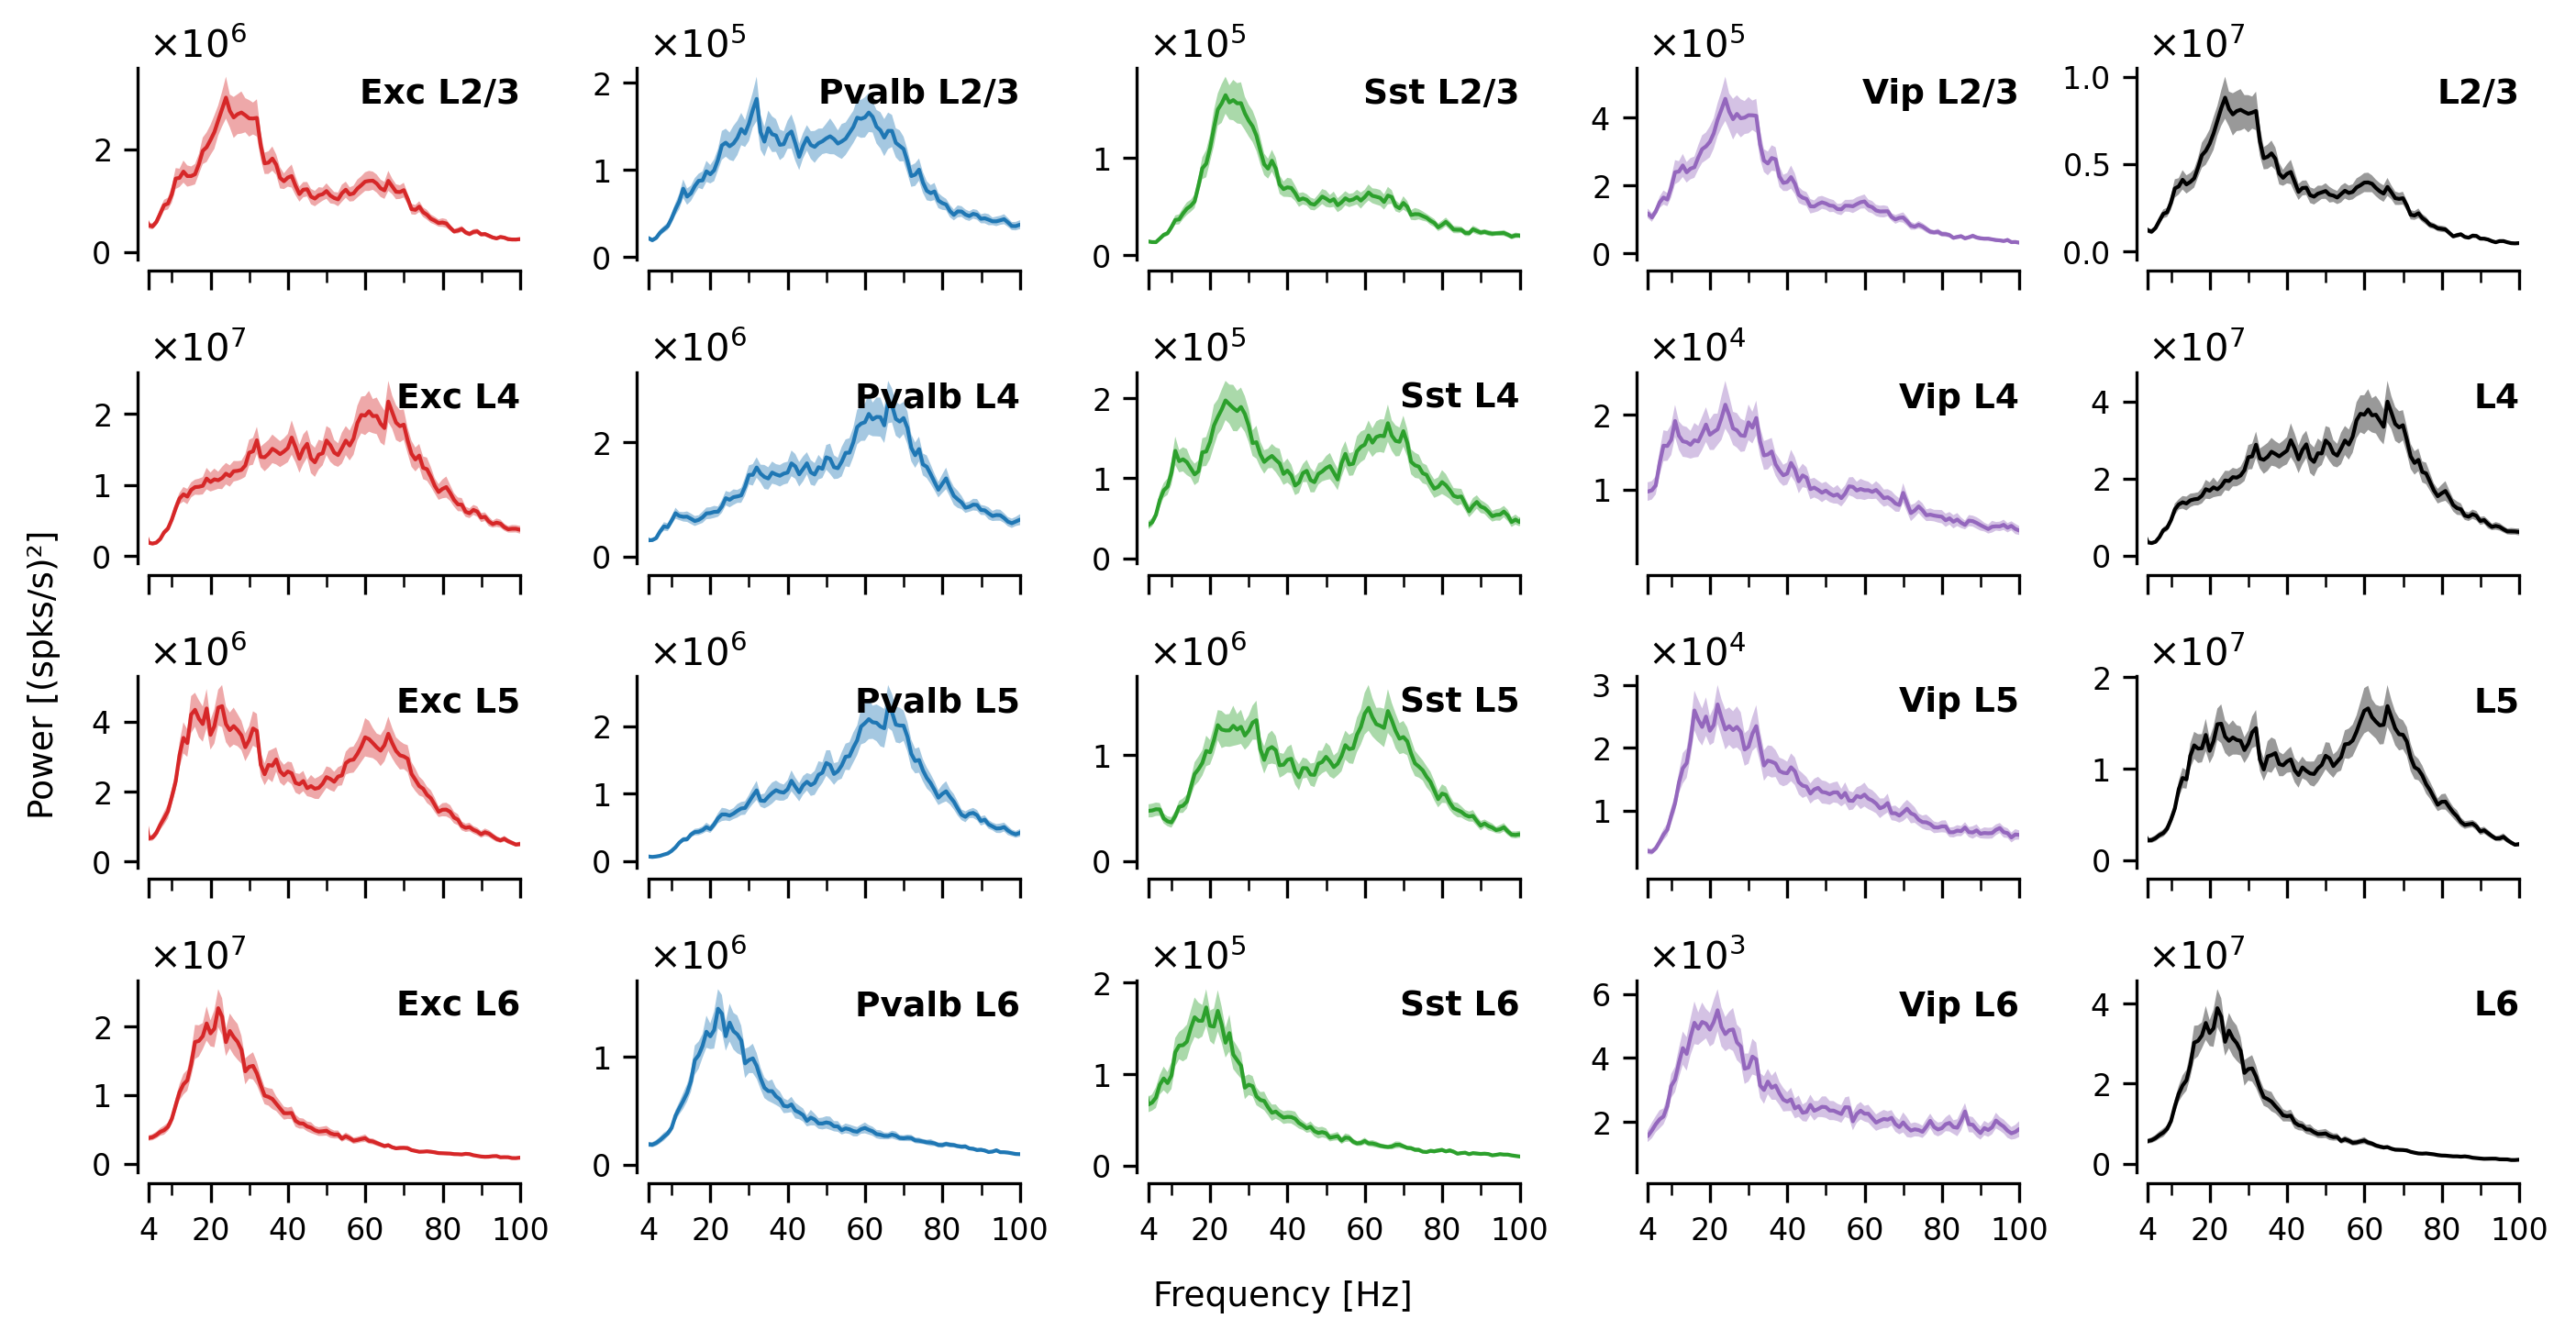

In [8]:
selected_cells = ["Exc", "Pvalb", "Sst", "Vip"]

fig, axes = plt.subplots(ncols=5, nrows=4, sharex=True, figsize=(9.5, 5), dpi=300)
fig.patch.set_facecolor("none")
f = power_pop_name_df.loc[0, "f"]
for (jj, cell), c in zip(enumerate(selected_cells), colors):
    data = power_pop_name_df.query(
        'condition == "no perturb"' + " & " + 'cell == "' + cell + '"'
    )
    print("cell {} layer_count {}".format(cell, data.layer.value_counts()))
    data.reset_index(inplace=True)

    for ii, layer in enumerate(layers[1:]):
        ax = axes[ii, jj]
        m = data.loc[
            (data["layer"] == layer).values,
            "mean",
        ].values[0]
        s = data.loc[
            (data["layer"] == layer).values,
            "se",
        ].values[0]
        
        ax.plot(
            f[1:],
            m[1:],
            color=c,
            linewidth=1,
        )
        # ax.axvline(contrast, color="lightgrey", linestyle="--", alpha=0.5)
        ax.fill_between(
            f[1:],
            m[1:] - 1.96 * s[1:],
            m[1:] + 1.96 * s[1:],
            facecolor=c,
            alpha=0.4,
        )

        sns.despine()  # Removes top and right spines by default
        # Position the left spine outward by 10 points
        ax.spines["left"].set_position(("outward", 3))
        # Position the bottom spine outward by 10 points
        ax.spines["bottom"].set_position(("outward", 3))

        ax.set_xlim([4, 100])
        # # Custom major ticks at powers of 2
        # major_locator = mticker.LogLocator(base=2)
        # ax.xaxis.set_major_locator(major_locator)
        # # Custom minor ticks at specific multiples within each major interval
        # minor_locator = mticker.LogLocator(base=2, subs=(0.5,)) # Example for minor ticks at 1.5 * 2^n
        # ax.xaxis.set_minor_locator(minor_locator)
        # # Format major tick labels
        # major_formatter = mticker.ScalarFormatter()
        # ax.xaxis.set_major_formatter(major_formatter)

        ax.set_xticks([4, 20, 40, 60, 80, 100])
        ax.set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=8)
        ax.set_xticks([10, 30, 50, 70, 90], minor=True)
        ax.tick_params(axis='x', which='major', length=5)
        ax.tick_params(axis='x', which='minor', length=3)

        # Format y-axis with scientific notation for large values
        formatter = ScalarFormatter(useMathText=True)
        formatter.set_powerlimits(
            (-3, 3)
        )  # Use scientific notation for values with >5 digits
        ax.yaxis.set_major_formatter(formatter)
        ax.ticklabel_format(axis="y", style="scientific", scilimits=(-3, 3))
        ax.tick_params(axis='y', labelsize=8)
        
        ax.text(
            1,
            0.95,
            cell + " " + layer,
            horizontalalignment="right",
            verticalalignment="top",
            fontsize=9,
            alpha=1,
            transform=ax.transAxes,
            fontweight="bold",
        )

data = power_layers_df.query('condition == "no perturb"')

jj += 1
for ii, layer in enumerate(layers[1:]):
    ax = axes[ii, jj]
    m = data.loc[
        (data["layer"] == layer).values,
        "mean",
    ].values[0]
    s = data.loc[
        (data["layer"] == layer).values,
        "se",
    ].values[0]
    ax.plot(
        f[1:],
        m[1:],
        color="k",
        linewidth=1,
    )
    ax.fill_between(
        f[1:], m[1:] - 1.96 * s[1:], m[1:] + 1.96 * s[1:], facecolor="k", alpha=0.4 
    )

    sns.despine()  # Removes top and right spines by default
    # Position the left spine outward by 10 points
    ax.spines["left"].set_position(("outward", 3))
    # Position the bottom spine outward by 10 points
    ax.spines["bottom"].set_position(("outward", 3))

    ax.set_xlim([4, 100])

    ax.set_xticks([4, 20, 40, 60, 80, 100])
    ax.set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=8)
    ax.set_xticks([10, 30, 50, 70, 90], minor=True)
    ax.tick_params(axis='x', which='major', length=5)
    ax.tick_params(axis='x', which='minor', length=3)

    # Format y-axis with scientific notation for large values
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_powerlimits(
        (-3, 2)
    )  # Use scientific notation for values with >5 digits
    ax.yaxis.set_major_formatter(formatter)
    ax.ticklabel_format(axis="y", style="scientific", scilimits=(-3, 2))
    ax.tick_params(axis='y', labelsize=8)

    ax.text(
        1,
        0.95,
        layer,
        horizontalalignment="right",
        verticalalignment="top",
        fontsize=9,
        alpha=1,
        transform=ax.transAxes,
        fontweight="bold",
    )

fig.supxlabel("Frequency [Hz]", fontsize=9, y=0.035)
fig.supylabel("Power [(spks/s)²]", fontsize=9)
fig.tight_layout()
fig.savefig(
    "paper_figs/fig1C_dg_power_spectrum_Jul17_2026.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

cell Exc layer_count L2/3    1
L4      1
L5      1
L6      1
Name: layer, dtype: int64
cell Pvalb layer_count L2/3    1
L4      1
L5      1
L6      1
Name: layer, dtype: int64
cell Sst layer_count L2/3    1
L4      1
L5      1
L6      1
Name: layer, dtype: int64
cell Vip layer_count L2/3    1
L4      1
L5      1
L6      1
Name: layer, dtype: int64


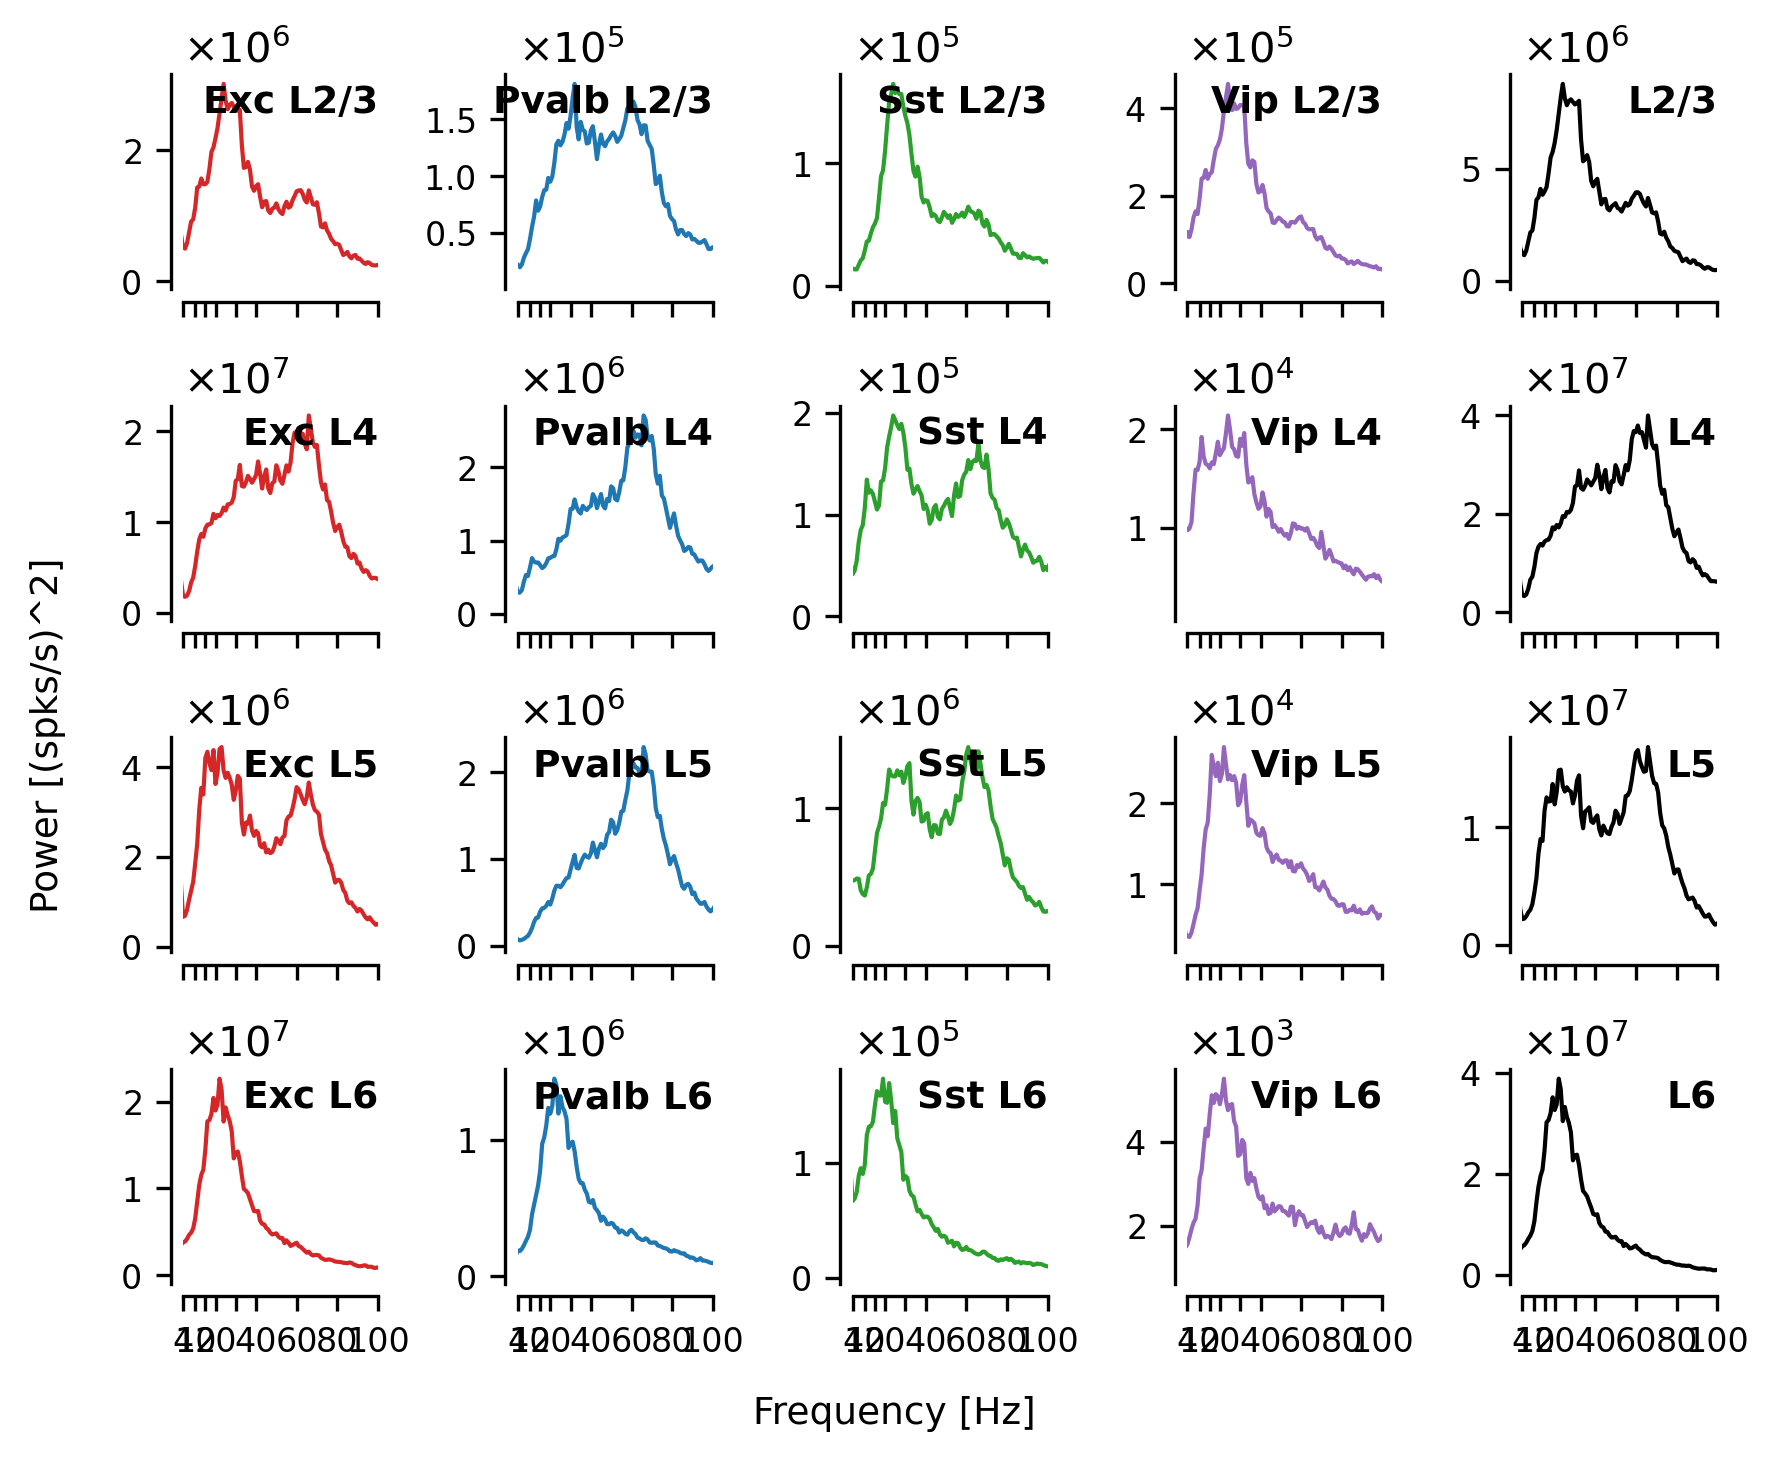

In [9]:
selected_cells = ["Exc", "Pvalb", "Sst", "Vip"]

fig, axes = plt.subplots(ncols=5, nrows=4, sharex=True, figsize=(6, 5), dpi=300)
fig.patch.set_facecolor("none")
f = power_pop_name_df.loc[0, "f"]
for (jj, cell), c in zip(enumerate(selected_cells), colors):
    data = power_pop_name_df.query(
        'condition == "no perturb"' + " & " + 'cell == "' + cell + '"'
    )
    print("cell {} layer_count {}".format(cell, data.layer.value_counts()))
    data.reset_index(inplace=True)

    for ii, layer in enumerate(layers[1:]):
        ax = axes[ii, jj]
        m = data.loc[
            (data["layer"] == layer).values,
            "mean",
        ].values[0]

        ax.plot(
            f[1:],
            m[1:],
            color=c,
            linewidth=1,
        )

        sns.despine()  # Removes top and right spines by default
        # Position the left spine outward by 10 points
        ax.spines["left"].set_position(("outward", 3))
        # Position the bottom spine outward by 10 points
        ax.spines["bottom"].set_position(("outward", 3))

        ax.set_xlim([4, 100])

        ax.set_xticks([4, 10, 15, 20, 30, 40, 60, 80, 100])
        ax.set_xticklabels([4, 10, "", 20, "", 40, 60, 80, 100], fontsize=8)

        # Format y-axis with scientific notation for large values
        formatter = ScalarFormatter(useMathText=True)
        formatter.set_powerlimits(
            (-3, 3)
        )  # Use scientific notation for values with >5 digits
        ax.yaxis.set_major_formatter(formatter)
        ax.ticklabel_format(axis="y", style="scientific", scilimits=(-3, 3))
        ax.tick_params(axis='y', labelsize=8)
        
        ax.text(
            1,
            0.95,
            cell + " " + layer,
            horizontalalignment="right",
            verticalalignment="top",
            fontsize=9,
            alpha=1,
            transform=ax.transAxes,
            fontweight="bold",
        )

data = power_layers_df.query('condition == "no perturb"')

jj += 1
for ii, layer in enumerate(layers[1:]):
    ax = axes[ii, jj]
    m = data.loc[
        (data["layer"] == layer).values,
        "mean",
    ].values[0]

    ax.plot(
        f[1:],
        m[1:],
        color="k",
        linewidth=1,
    )

    sns.despine()  # Removes top and right spines by default
    # Position the left spine outward by 10 points
    ax.spines["left"].set_position(("outward", 3))
    # Position the bottom spine outward by 10 points
    ax.spines["bottom"].set_position(("outward", 3))

    ax.set_xlim([4, 100])

    ax.set_xticks([4, 10, 15, 20, 30, 40, 60, 80, 100])
    ax.set_xticklabels([4, 10, "", 20, "", 40, 60, 80, 100], fontsize=8)

    # Format y-axis with scientific notation for large values
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_powerlimits(
        (-3, 2)
    )  # Use scientific notation for values with >5 digits
    ax.yaxis.set_major_formatter(formatter)
    ax.ticklabel_format(axis="y", style="scientific", scilimits=(-3, 2))
    ax.tick_params(axis='y', labelsize=8)

    ax.text(
        1,
        0.95,
        layer,
        horizontalalignment="right",
        verticalalignment="top",
        fontsize=9,
        alpha=1,
        transform=ax.transAxes,
        fontweight="bold",
    )

fig.supxlabel("Frequency [Hz]", fontsize=9, y=0.035)
fig.supylabel("Power [(spks/s)^2]", fontsize=9)
fig.tight_layout()
# fig.savefig(
#     "paper_figs/dg_power_spectrum_Oct8_26.pdf",
#     dpi=300,
#     bbox_inches="tight",
#     transparent=True,
# )

In [10]:
power_layers_df

,condition,layer,power,f,mean,std,se
0,no perturb,L1,"[[524.8277932203187, 11993.11863047429, 25320....","[0.0, 0.9992000000000015, 1.998400000000003, 2...","[369.570148367966, 13850.67337406819, 19812.09...","[321.402602631343, 9664.084884818132, 15033.08...","[35.933903381451785, 1080.4775371390783, 1680...."
1,no perturb,L2/3,"[[73427.96216739286, 1369482.4412082045, 32710...","[0.0, 0.9992000000000015, 1.998400000000003, 2...","[27964.01748979795, 1085755.1688773395, 246973...","[31909.568389464792, 767009.7933665975, 203391...","[3567.5982025760877, 85754.30186878896, 227398..."
2,no perturb,L4,"[[37439.9536899821, 4054502.5783625897, 126281...","[0.0, 0.9992000000000015, 1.998400000000003, 2...","[43543.15361062485, 4015674.277344895, 1146928...","[58715.5576601182, 2302613.7638438544, 6635783...","[6564.598913241639, 257440.0450940753, 741903...."
3,no perturb,L5,"[[89548.66313543354, 1646534.8260391678, 77791...","[0.0, 0.9992000000000015, 1.998400000000003, 2...","[104233.08053859291, 2636380.200580618, 511662...","[154159.431752365, 1564098.89626586, 3109014.0...","[17235.54843855138, 174871.57277914273, 347598..."
4,no perturb,L6,"[[8979.52291779367, 4111951.6597038736, 926213...","[0.0, 0.9992000000000015, 1.998400000000003, 2...","[102868.7824914525, 3963710.1468842616, 575170...","[160833.5517300252, 2606328.2112495457, 376808...","[17981.737736553263, 291396.3526014708, 421284..."


In [11]:
mean_power_cond = power_layers_df.groupby(["condition"]).agg(
    {
        "mean": list,
    }
)
mean_power_cond["max"] = mean_power_cond["mean"].apply(
    lambda row: np.max(np.vstack(np.asanyarray(row)), axis=0)
)
mean_power_cond.rename(columns={"index": "condition"})
mean_power_cond.reset_index(inplace=True)


def get_norm_power(row):
    max_values = mean_power_cond.loc[
        mean_power_cond["condition"].isin([row["condition"]]).values,
        "max",
    ].values[0]
    # print(row["contrast"])
    norm_power = row["mean"] / max_values
    # print(np.max(norm_power))
    return norm_power


power_layers_df["norm power"] = power_layers_df.apply(
    lambda row: get_norm_power(row), axis=1
)

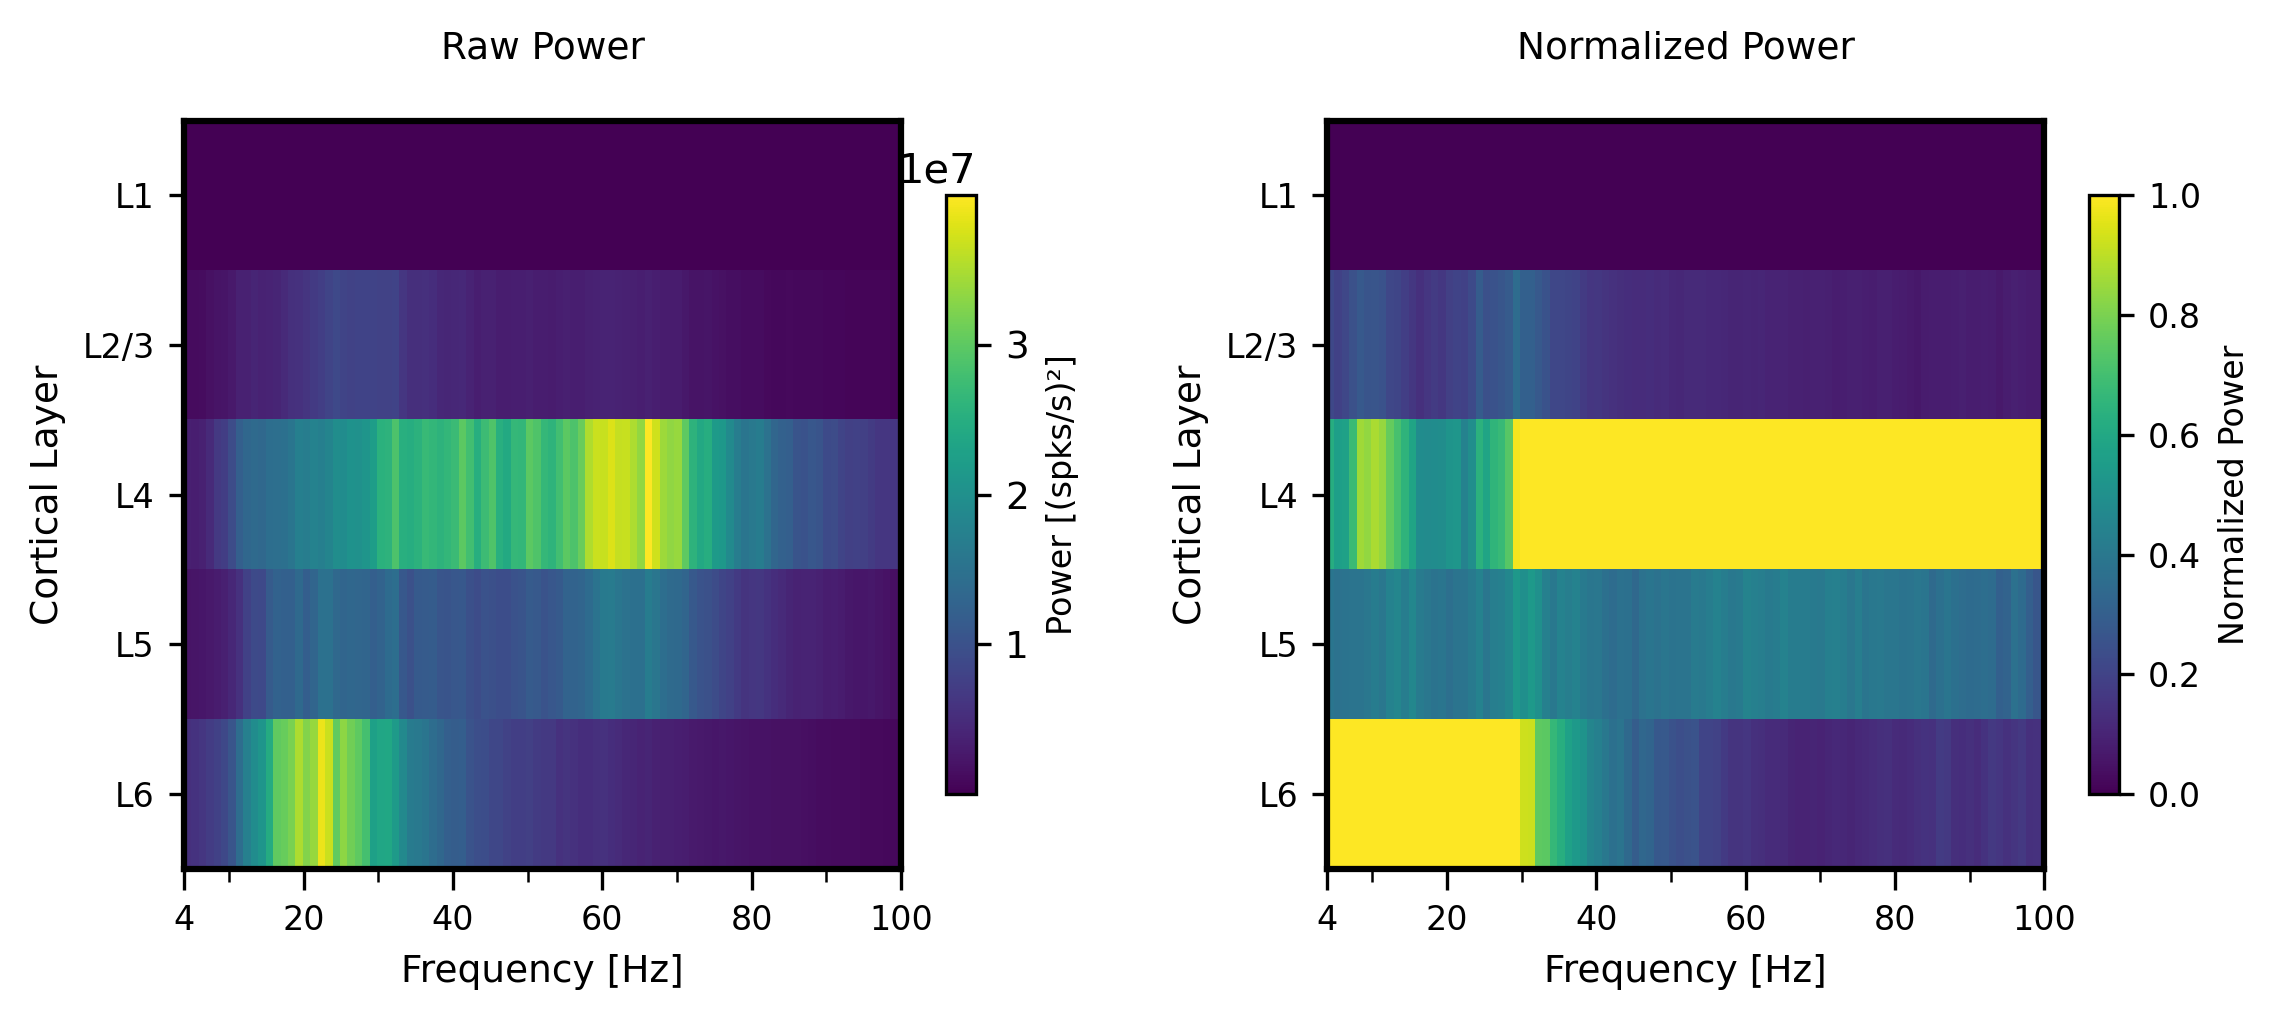

In [12]:
# Create laminar power colormap plots
fig, axes = plt.subplots(ncols=2, nrows=1, figsize=(7.75, 3.5), dpi=300)
fig.patch.set_facecolor("white")

# Filter data for no perturb condition and contrast 0.8
data = power_layers_df.query('condition == "no perturb"')

# Get frequency array
f = data.loc[data.index[0], "f"]

# Create 2D arrays for power data - include all layers
layers_all = layers  # Include L1
power_matrix = np.zeros((len(layers_all), len(f[1:])))  # Exclude first frequency point
power_matrix_norm = np.zeros((len(layers_all), len(f[1:])))

# Fill the matrices
for i, layer in enumerate(layers_all):
    layer_data = data[data["layer"] == layer]
    if len(layer_data) > 0:
        power = layer_data["mean"].iloc[0][1:]  # Exclude first frequency point
        power_matrix[i, :] = power

# Normalize by maximum power per frequency
max_power_per_freq = np.max(power_matrix, axis=0)
for i in range(power_matrix.shape[0]):
    power_matrix_norm[i, :] = power_matrix[i, :] / max_power_per_freq

# First panel: Raw power
im1 = axes[0].imshow(
    power_matrix,
    aspect="auto",
    origin="upper",  # Invert y-axis so L1 is on top
    extent=[f[1], f[-1], len(layers_all), 0],
    cmap="viridis",
)
axes[0].set_xlabel("Frequency [Hz]", fontsize=9)
axes[0].set_ylabel("Cortical Layer", fontsize=9)
axes[0].set_title("Raw Power", fontsize=9, pad=15)
axes[0].set_yticks(np.arange(len(layers_all)) + 0.5)
axes[0].set_yticklabels(layers_all, fontsize=8)
axes[0].set_xlim([4, 100])
axes[0].set_xticks([4, 20, 40, 60, 80, 100])
axes[0].set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=8)
axes[0].set_xticks([10, 30, 50, 70, 90], minor=True)
axes[0].tick_params(axis='x', which='major', length=5)
axes[0].tick_params(axis='x', which='minor', length=3)

# Style the axes
# axes[0].spines["top"].set_visible(False)
# axes[0].spines["right"].set_visible(False)
axes[0].spines["top"].set_linewidth(1.5)
axes[0].spines["right"].set_linewidth(1.5)
axes[0].spines["left"].set_linewidth(1.5)
axes[0].spines["bottom"].set_linewidth(1.5)

# Add colorbar for first panel
cbar1 = plt.colorbar(im1, ax=axes[0], shrink=0.8)
cbar1.set_label("Power [(spks/s)²]", fontsize=8)
cbar1.ax.tick_params(labelsize=9)

# Second panel: Normalized power
im2 = axes[1].imshow(
    power_matrix_norm,
    aspect="auto",
    origin="upper",  # Invert y-axis so L1 is on top
    extent=[f[1], f[-1], len(layers_all), 0],
    cmap="viridis",
    vmin=0,
    vmax=1,
)
axes[1].set_xlabel("Frequency [Hz]", fontsize=9)
axes[1].set_ylabel("Cortical Layer", fontsize=9)
axes[1].set_title(
    "Normalized Power", fontsize=9, pad=15
)
axes[1].set_yticks(np.arange(len(layers_all)) + 0.5)
axes[1].set_yticklabels(layers_all, fontsize=8)
axes[1].set_xlim([4, 100])
axes[1].set_xticks([4, 20, 40, 60, 80, 100])
axes[1].set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=8)
axes[1].set_xticks([10, 30, 50, 70, 90], minor=True)
axes[1].tick_params(axis='x', which='major', length=5)
axes[1].tick_params(axis='x', which='minor', length=3)

# Style the axes
# axes[1].spines["top"].set_visible(False)
# axes[1].spines["right"].set_visible(False)
axes[1].spines["top"].set_linewidth(1.5)
axes[1].spines["right"].set_linewidth(1.5)
axes[1].spines["left"].set_linewidth(1.5)
axes[1].spines["bottom"].set_linewidth(1.5)

# Add colorbar for second panel
cbar2 = plt.colorbar(im2, ax=axes[1], shrink=0.8)
cbar2.set_label("Normalized Power", fontsize=8)
cbar2.ax.tick_params(labelsize=8)

# Add overall title with better positioning
# fig.suptitle(
#     "Laminar Power (Contrast 0.8)",
#     fontsize=8,
#     fontweight="bold",
#     y=0.95,
# )

# Improve layout
# plt.tight_layout(rect=[0, 0, 1, 0.92])
fig.tight_layout()
fig.savefig(
    "paper_figs/laminar_power_colormap_no_smoothing_Oct8_2026.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=False,
    facecolor="white",
)